# Instituto / Universidad: **CENTRO UNIVERSITARIO UAEM ZUMPANGO**

## Programa Educativo: Ingeniería en Computación

### Asignatura: Investigación de Operaciones

---

# Práctica 1. Algoritmo de Expansión Mínima (Prim)

**Actividad integradora:** Implementación de Modelos de Investigación de Operaciones mediante Python y Jupyter Notebook

**Periodo:** 2026-B

**Integrantes del equipo:**

| No. | Nombre completo |
|:---:|:----------------|
| 1 | Fernando Dante Rodriguez Silva |  
| 2 | Jonathan Alberto López Fabián |
| 3 | Brayan Michel Aguilar Torres |  

**Fecha de elaboración:** 16 de noviembre de 2026

**Herramientas:** Python 3, Jupyter Notebook, NetworkX, Matplotlib, NumPy, Pandas y SciPy.

---
# 1. Título del problema

**Diseño del cableado de fibra óptica de menor costo para la red troncal de un campus universitario**

--- 
# 2. Descripción y planteamiento

Un campus cuenta con **8 sitios** que deben quedar interconectados en una misma red de datos mediante fibra óptica: el *Data Center* (DC), el Laboratorio de Cómputo (LAB), la Biblioteca (BIB), Rectoría (REC), el Edificio A (EDA), el Edificio B (EDB), la Cafetería (CAF) y el Gimnasio (GYM).

Por razones de obra civil sólo se pueden tender enlaces entre ciertos pares de sitios (**14 enlaces posibles**), y cada uno tiene una longitud en **metros** de zanja y fibra. Todos los sitios deben quedar conectados (directa o indirectamente) con la **menor longitud total de cable**.

**Relación con las Tecnologías de la Información:** este es el problema clásico de diseño de topologías de red de costo mínimo (cableado estructurado, enlaces de fibra entre edificios, redes de sensores/IoT). En teoría de grafos corresponde a encontrar el **árbol de expansión mínima** (*Minimum Spanning Tree*, MST) de una red **no dirigida y ponderada**.

---
# 3. Formulación matemática

Sea la red $R=(N,A)$ con $N$ el conjunto de nodos ($|N|=n=8$) y $A$ el conjunto de arcos no dirigidos $(i,j)$ con longitud $c_{ij}$.

**Variable de decisión:**

$$x_{ij}=\begin{cases}1 & \text{si el enlace } (i,j) \text{ se tiende}\\ 0 & \text{en otro caso}\end{cases}$$

**Función objetivo** (minimizar los metros totales de cable):

$$\min Z=\sum_{(i,j)\in A} c_{ij}\,x_{ij}$$

**Restricciones:**

$$\sum_{(i,j)\in A} x_{ij}=n-1 \qquad \text{(un árbol de } n \text{ nodos tiene exactamente } n-1 \text{ arcos)}$$

$$\sum_{(i,j)\in A(S)} x_{ij}\le |S|-1 \quad \forall\, S\subset N,\ S\neq\emptyset \qquad \text{(no se forman ciclos)}$$

Como se menciona en clase, plantearlo como programa lineal exige muchas restricciones de ciclos, por lo que se resuelve con un **algoritmo especializado**: el **algoritmo de Prim**.

**Algoritmo de Prim (resumen):**

1. Elegir un nodo inicial cualquiera; forma el conjunto *conectado* $C$. El resto forma el conjunto *no conectado* $\bar{C}$.
2. Entre todos los arcos que unen un nodo de $C$ con un nodo de $\bar{C}$, elegir el de **menor longitud** (los empates se resuelven arbitrariamente).
3. Pasar el nuevo nodo de $\bar{C}$ a $C$ y agregar el arco al árbol.
4. Repetir hasta que $C=N$, es decir, en $n-1=7$ pasos.

---
# 4. Importación de bibliotecas

Se importan: **NumPy** (matrices), **Pandas** (tablas de datos), **NetworkX** (estructura de grafo y verificación del resultado) y **Matplotlib** (gráficas).

In [1]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt


print("NumPy     :", np.__version__)
print("Pandas    :", pd.__version__)
print("NetworkX  :", nx.__version__)
print("Bibliotecas importadas correctamente.")

NumPy     : 2.5.4
Pandas    : 3.0.6
NetworkX  : 3.7
Bibliotecas importadas correctamente.


---
# 5. Definición de datos

Se definen los nodos (sitios del campus) y los arcos con su longitud en metros. Los datos se guardan también en el archivo complementario `p1_aristas_campus.csv`.

Además se fijan las **coordenadas** de cada nodo para que todas las gráficas del notebook mantengan el mismo dibujo y se pueda ver cómo evoluciona la solución paso a paso.

In [2]:
nodos = ["DC", "LAB", "BIB", "REC", "EDA", "EDB", "CAF", "GYM"]

nombre_sitio = {
    "DC": "Data Center", "LAB": "Lab. de Cómputo", "BIB": "Biblioteca", "REC": "Rectoría",
    "EDA": "Edificio A", "EDB": "Edificio B", "CAF": "Cafetería", "GYM": "Gimnasio",
}

# (origen, destino, metros de fibra)
aristas = [
    ("DC", "LAB", 120), ("DC", "BIB", 200), ("DC", "REC", 150),
    ("LAB", "BIB", 90), ("LAB", "EDA", 180),
    ("BIB", "REC", 110), ("BIB", "EDB", 160),
    ("REC", "EDB", 140), ("REC", "GYM", 250),
    ("EDA", "EDB", 130), ("EDA", "CAF", 100),
    ("EDB", "CAF", 170), ("EDB", "GYM", 210),
    ("CAF", "GYM", 95),
]

df_aristas = pd.DataFrame(aristas, columns=["origen", "destino", "metros"])
df_aristas.to_csv("p1_aristas_campus.csv", index=False)

print("Número de nodos :", len(nodos))
print("Número de arcos :", len(aristas))
print()
print(df_aristas.to_string(index=False))

# Grafo no dirigido y ponderado
G = nx.Graph()
G.add_nodes_from(nodos)
G.add_weighted_edges_from(aristas)

# Coordenadas fijas para dibujar siempre igual
pos = {"DC": (0, 2), "LAB": (2, 3.6), "BIB": (2.2, 2.0), "REC": (1.6, 0.2),
       "EDA": (4.6, 3.6), "EDB": (4.2, 1.6), "CAF": (6.5, 3.0), "GYM": (6.4, 0.6)}

Número de nodos : 8
Número de arcos : 14

origen destino  metros
    DC     LAB     120
    DC     BIB     200
    DC     REC     150
   LAB     BIB      90
   LAB     EDA     180
   BIB     REC     110
   BIB     EDB     160
   REC     EDB     140
   REC     GYM     250
   EDA     EDB     130
   EDA     CAF     100
   EDB     CAF     170
   EDB     GYM     210
   CAF     GYM      95


---
## 5.1 Funciones auxiliares de graficación

Se define una función que dibuja la red resaltando, en cada paso: los nodos ya **conectados** (verde), el **nodo recién agregado** (naranja), los arcos **candidatos** de la frontera (naranja punteado), los arcos ya **seleccionados** del árbol (verde grueso) y el arco **elegido** en el paso actual (rojo).

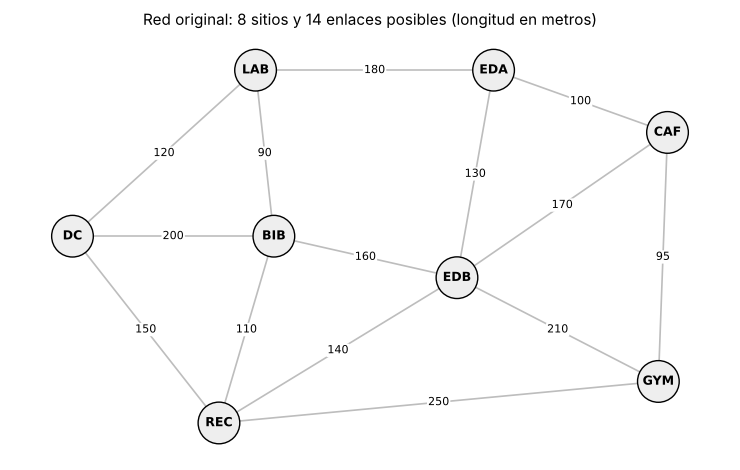

In [3]:
def dibujar(G, pos, titulo, arbol=(), candidatas=(), elegida=None, conectados=(), nuevo=None, ax=None):
    """Dibuja la red con el estado actual del algoritmo."""
    propio = ax is None
    if propio:
        fig, ax = plt.subplots(figsize=(7.5, 4.8))
    arbol_set = {frozenset((u, v)) for u, v, *_ in arbol}
    cand_set = {frozenset((u, v)) for u, v, *_ in candidatas}
    eleg = frozenset(elegida[:2]) if elegida else None

    # arcos base
    otros = [(u, v) for u, v in G.edges() if frozenset((u, v)) not in arbol_set | cand_set]
    nx.draw_networkx_edges(G, pos, edgelist=otros, edge_color="#bdbdbd", width=1.2, ax=ax)
    # candidatas
    cands = [(u, v) for u, v in G.edges() if frozenset((u, v)) in cand_set and frozenset((u, v)) != eleg]
    nx.draw_networkx_edges(G, pos, edgelist=cands, edge_color="#fb8c00", width=2, style="dashed", ax=ax)
    # arbol
    arb = [(u, v) for u, v in G.edges() if frozenset((u, v)) in arbol_set and frozenset((u, v)) != eleg]
    nx.draw_networkx_edges(G, pos, edgelist=arb, edge_color="#2e7d32", width=4, ax=ax)
    # elegida
    if eleg:
        el = [(u, v) for u, v in G.edges() if frozenset((u, v)) == eleg]
        nx.draw_networkx_edges(G, pos, edgelist=el, edge_color="#d32f2f", width=5, ax=ax)

    colores = []
    for n in G.nodes():
        if n == nuevo:
            colores.append("#ffb74d")
        elif n in conectados:
            colores.append("#a5d6a7")
        else:
            colores.append("#eeeeee")
    nx.draw_networkx_nodes(G, pos, node_color=colores, node_size=900, edgecolors="black", ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=9, font_weight="bold", ax=ax)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"),
                                 font_size=8, ax=ax, rotate=False, bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none"))
    ax.set_title(titulo, fontsize=11)
    ax.axis("off")
    if propio:
        plt.tight_layout()
        plt.show()


# Grafica de la red original (todos los enlaces posibles)

dibujar(G, pos, "Red original: 8 sitios y 14 enlaces posibles (longitud en metros)")

---
# 6. Desarrollo del algoritmo

## 6.1 Representación de la red: matriz de adyacencia ponderada

Como se vio en clase, una red ponderada se puede representar con una **matriz de adyacencia (matriz de pesos)**: en la posición $(i,j)$ se coloca la longitud del arco, `0` en la diagonal y una constante **M** (aquí $\infty$) cuando el arco no existe. Al ser una red **no dirigida**, la matriz debe ser **simétrica**.

Matriz de adyacencia ponderada (M = no existe arco):

      DC  LAB  BIB  REC  EDA  EDB  CAF  GYM
DC     0  120  200  150    M    M    M    M
LAB  120    0   90    M  180    M    M    M
BIB  200   90    0  110    M  160    M    M
REC  150    M  110    0    M  140    M  250
EDA    M  180    M    M    0  130  100    M
EDB    M    M  160  140  130    0  170  210
CAF    M    M    M    M  100  170    0   95
GYM    M    M    M  250    M  210   95    0

¿La matriz es simétrica? -> True


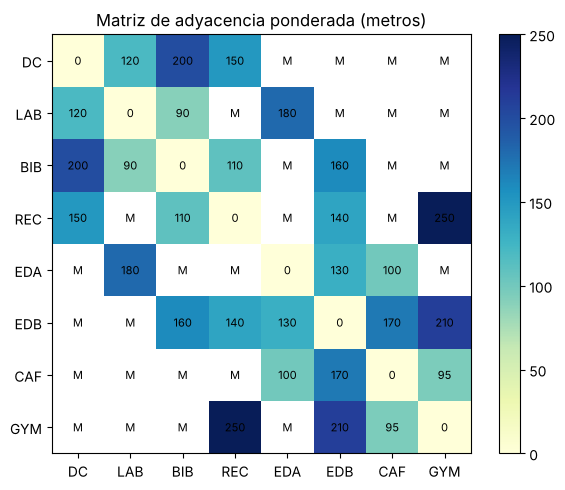

In [4]:
n = len(nodos)
idx = {nom: i for i, nom in enumerate(nodos)}

M = np.full((n, n), np.inf)
np.fill_diagonal(M, 0)
for u, v, w in aristas:
    M[idx[u], idx[v]] = w
    M[idx[v], idx[u]] = w

# Para mostrar: 'M' donde no hay arco
df_M = pd.DataFrame([["M" if np.isinf(x) else int(x) for x in fila] for fila in M],
                    index=nodos, columns=nodos)
print("Matriz de adyacencia ponderada (M = no existe arco):\n")
print(df_M.to_string())
print("\n¿La matriz es simétrica? ->", np.allclose(M, M.T, equal_nan=True))

# Mapa de calor
Mp = np.where(np.isinf(M), np.nan, M)
fig, ax = plt.subplots(figsize=(6.2, 5))
im = ax.imshow(Mp, cmap="YlGnBu")
ax.set_xticks(range(n)); ax.set_xticklabels(nodos)
ax.set_yticks(range(n)); ax.set_yticklabels(nodos)
for i in range(n):
    for j in range(n):
        ax.text(j, i, "M" if np.isinf(M[i, j]) else int(M[i, j]), ha="center", va="center", fontsize=8)
ax.set_title("Matriz de adyacencia ponderada (metros)")
plt.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

---
## 6.2 Verificación previa: la red debe ser conexa

El algoritmo de Prim sólo tiene solución si la red es **conexa** (existe al menos una ruta entre cada par de nodos). También se calcula el **grado** de cada nodo (número de enlaces posibles que salen de él) para conocer qué sitios tienen más opciones de conexión.

¿La red es conexa? -> True
Grado de cada nodo: {'DC': 3, 'LAB': 3, 'BIB': 4, 'REC': 4, 'EDA': 3, 'EDB': 5, 'CAF': 3, 'GYM': 3}
Suma de las longitudes de TODOS los enlaces posibles: 2105 m


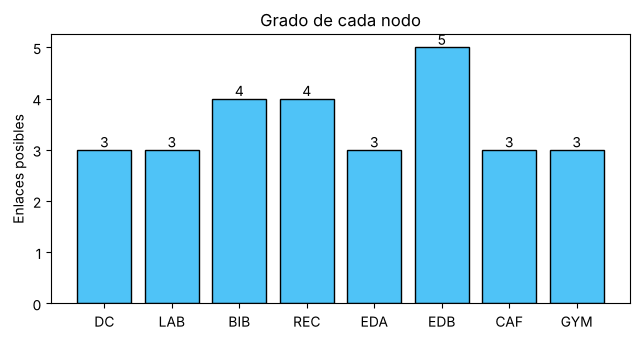

In [5]:
print("¿La red es conexa? ->", nx.is_connected(G))
grados = dict(G.degree())
print("Grado de cada nodo:", grados)
print("Suma de las longitudes de TODOS los enlaces posibles:", sum(w for _, _, w in aristas), "m")

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.bar(list(grados.keys()), list(grados.values()), color="#4fc3f7", edgecolor="black")
ax.set_ylabel("Enlaces posibles")
ax.set_title("Grado de cada nodo")
for i, v in enumerate(grados.values()):
    ax.text(i, v + 0.05, str(v), ha="center")
plt.tight_layout()
plt.show()

---
## 6.3 Implementación del algoritmo de Prim (paso 0: nodo inicial)

Se implementa Prim como un **generador**: cada vez que se invoca `next(pasos)` ejecuta **una sola iteración** y devuelve el estado (arcos de la frontera, arco elegido, conjunto conectado y costo acumulado). Así se puede avanzar **celda por celda**.

En cada iteración:

1. Se construye la **frontera**: arcos que van de un nodo conectado a uno no conectado.
2. Se elige el arco de **menor longitud**.
3. Se agrega el nodo nuevo al conjunto conectado y se suma su longitud al costo total.

Se inicia en el **Data Center (DC)**; cualquier otro nodo daría el mismo costo mínimo.

PASO 0: se inicia en el nodo DC
Conjunto conectado C   : ['DC']
Conjunto no conectado  : ['LAB', 'BIB', 'REC', 'EDA', 'EDB', 'CAF', 'GYM']


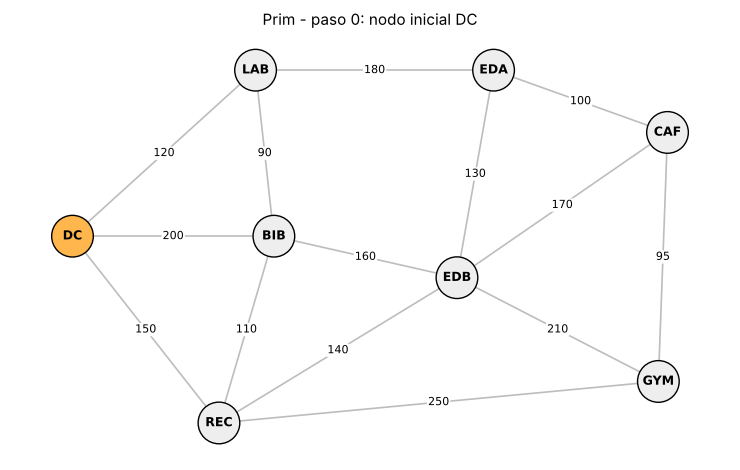

In [6]:
def prim_pasos(G, inicio):
    conectados = [inicio]
    arbol, total = [], 0
    while len(conectados) < G.number_of_nodes():
        frontera = []
        for u in conectados:
            for v in G[u]:
                if v not in conectados:
                    frontera.append((u, v, G[u][v]["weight"]))
        frontera.sort(key=lambda e: e[2])
        u, v, w = frontera[0]                    # arco de menor longitud
        conectados.append(v)
        arbol.append((u, v, w))
        total += w
        yield {"k": len(arbol), "frontera": frontera, "elegida": (u, v, w),
               "conectados": list(conectados), "arbol": list(arbol), "total": total}


def mostrar_paso(p):
    print(f"ITERACIÓN {p['k']}")
    print("Conjunto conectado C :", p["conectados"][:-1], "-> se agrega", p["conectados"][-1])
    print("Conjunto no conectado:", [n for n in nodos if n not in p["conectados"]])
    tabla = pd.DataFrame(p["frontera"], columns=["desde (C)", "hacia (no C)", "metros"])
    tabla["decisión"] = ["<-- MENOR: se elige" if i == 0 else "" for i in range(len(tabla))]
    print("\nArcos de la frontera (ordenados por longitud):")
    print(tabla.to_string(index=False))
    u, v, w = p["elegida"]
    print(f"\nArco elegido: ({u}, {v}) con {w} m  |  Costo acumulado = {p['total']} m")
    dibujar(G, pos, f"Prim - iteración {p['k']}: se agrega el arco ({u}, {v}) = {w} m  |  acumulado = {p['total']} m",
            arbol=p["arbol"][:-1], candidatas=p["frontera"], elegida=p["elegida"],
            conectados=p["conectados"], nuevo=p["conectados"][-1])


pasos = prim_pasos(G, "DC")

print("PASO 0: se inicia en el nodo DC")
print("Conjunto conectado C   :", ["DC"])
print("Conjunto no conectado  :", [n for n in nodos if n != "DC"])
dibujar(G, pos, "Prim - paso 0: nodo inicial DC", conectados=["DC"], nuevo="DC")

---
# 7. Ejecución paso a paso

Cada celda siguiente ejecuta **una iteración** del algoritmo (`next(pasos)`) y la grafica. En la gráfica: nodos verdes = conectados, nodo naranja = recién agregado, líneas naranjas punteadas = candidatas de la frontera, línea roja = arco elegido y líneas verdes gruesas = arcos ya incluidos en el árbol.

## Iteración 1 de 7

Desde DC los únicos arcos posibles son DC–LAB (120), DC–REC (150) y DC–BIB (200). Se elige el menor.

ITERACIÓN 1
Conjunto conectado C : ['DC'] -> se agrega LAB
Conjunto no conectado: ['BIB', 'REC', 'EDA', 'EDB', 'CAF', 'GYM']

Arcos de la frontera (ordenados por longitud):
desde (C) hacia (no C)  metros            decisión
       DC          LAB     120 <-- MENOR: se elige
       DC          REC     150                    
       DC          BIB     200                    

Arco elegido: (DC, LAB) con 120 m  |  Costo acumulado = 120 m


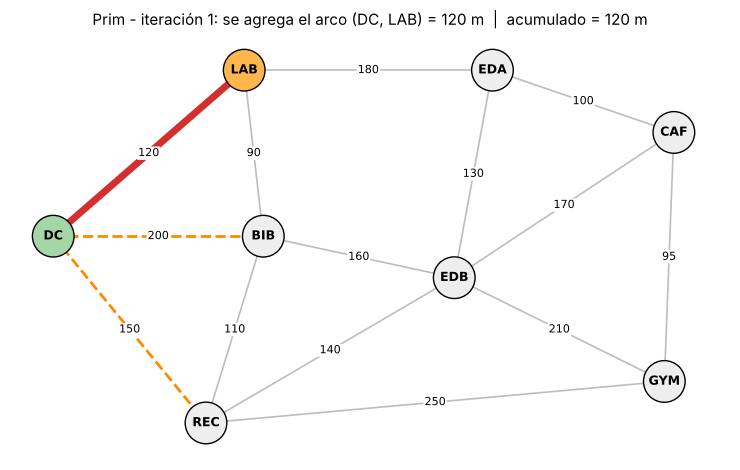

In [7]:
paso = next(pasos)
mostrar_paso(paso)

## Iteración 2 de 7

Ahora la frontera incluye los arcos de DC y de LAB. Aparece LAB–BIB con sólo 90 m, el más corto de la frontera.

ITERACIÓN 2
Conjunto conectado C : ['DC', 'LAB'] -> se agrega BIB
Conjunto no conectado: ['REC', 'EDA', 'EDB', 'CAF', 'GYM']

Arcos de la frontera (ordenados por longitud):
desde (C) hacia (no C)  metros            decisión
      LAB          BIB      90 <-- MENOR: se elige
       DC          REC     150                    
      LAB          EDA     180                    
       DC          BIB     200                    

Arco elegido: (LAB, BIB) con 90 m  |  Costo acumulado = 210 m


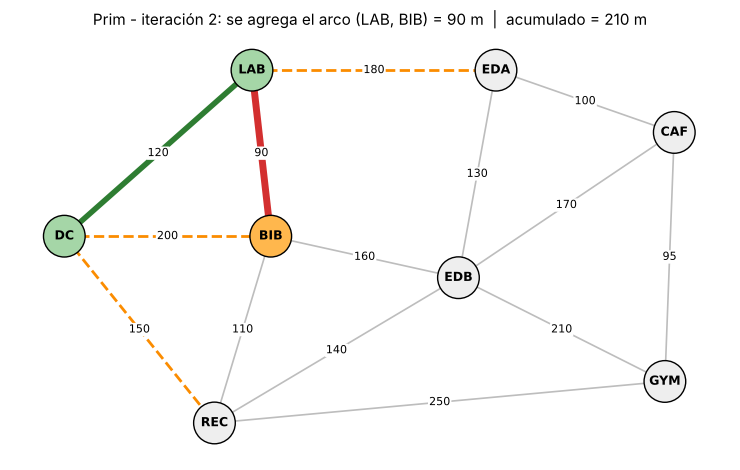

In [8]:
paso = next(pasos)
mostrar_paso(paso)

## Iteración 3 de 7

Con BIB conectado se abren BIB–REC (110) y BIB–EDB (160); el de menor longitud es BIB–REC.

ITERACIÓN 3
Conjunto conectado C : ['DC', 'LAB', 'BIB'] -> se agrega REC
Conjunto no conectado: ['EDA', 'EDB', 'CAF', 'GYM']

Arcos de la frontera (ordenados por longitud):
desde (C) hacia (no C)  metros            decisión
      BIB          REC     110 <-- MENOR: se elige
       DC          REC     150                    
      BIB          EDB     160                    
      LAB          EDA     180                    

Arco elegido: (BIB, REC) con 110 m  |  Costo acumulado = 320 m


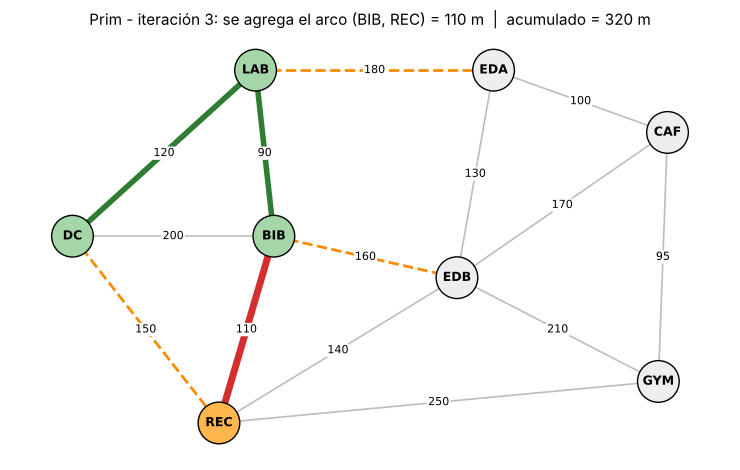

In [9]:
paso = next(pasos)
mostrar_paso(paso)

## Iteración 4 de 7

Con REC conectado aparece REC–EDB (140), que resulta ser el menor de la frontera.

ITERACIÓN 4
Conjunto conectado C : ['DC', 'LAB', 'BIB', 'REC'] -> se agrega EDB
Conjunto no conectado: ['EDA', 'CAF', 'GYM']

Arcos de la frontera (ordenados por longitud):
desde (C) hacia (no C)  metros            decisión
      REC          EDB     140 <-- MENOR: se elige
      BIB          EDB     160                    
      LAB          EDA     180                    
      REC          GYM     250                    

Arco elegido: (REC, EDB) con 140 m  |  Costo acumulado = 460 m


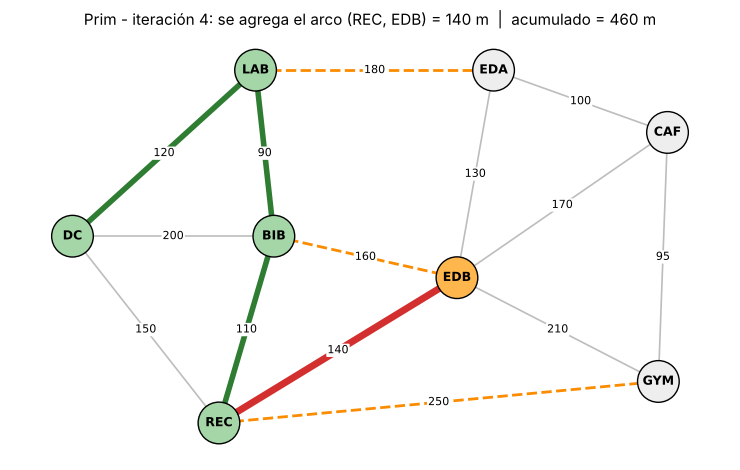

In [10]:
paso = next(pasos)
mostrar_paso(paso)

## Iteración 5 de 7

Con EDB conectado se abre EDB–EDA (130), más barato que LAB–EDA (180).

ITERACIÓN 5
Conjunto conectado C : ['DC', 'LAB', 'BIB', 'REC', 'EDB'] -> se agrega EDA
Conjunto no conectado: ['CAF', 'GYM']

Arcos de la frontera (ordenados por longitud):
desde (C) hacia (no C)  metros            decisión
      EDB          EDA     130 <-- MENOR: se elige
      EDB          CAF     170                    
      LAB          EDA     180                    
      EDB          GYM     210                    
      REC          GYM     250                    

Arco elegido: (EDB, EDA) con 130 m  |  Costo acumulado = 590 m


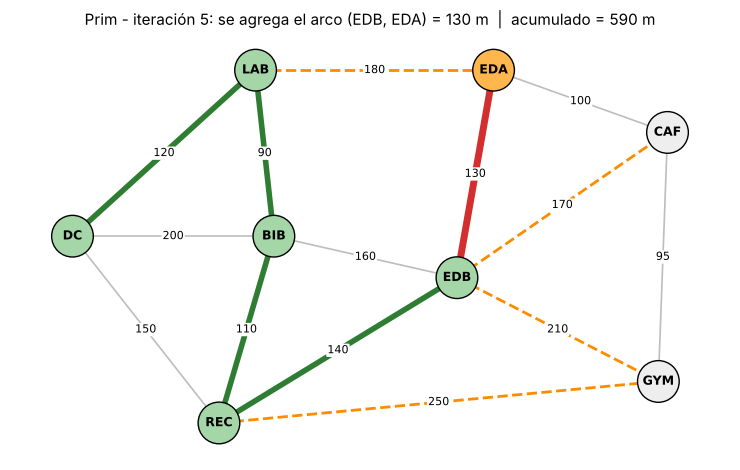

In [11]:
paso = next(pasos)
mostrar_paso(paso)

## Iteración 6 de 7

Con EDA conectado aparece EDA–CAF (100), el menor de la frontera.

ITERACIÓN 6
Conjunto conectado C : ['DC', 'LAB', 'BIB', 'REC', 'EDB', 'EDA'] -> se agrega CAF
Conjunto no conectado: ['GYM']

Arcos de la frontera (ordenados por longitud):
desde (C) hacia (no C)  metros            decisión
      EDA          CAF     100 <-- MENOR: se elige
      EDB          CAF     170                    
      EDB          GYM     210                    
      REC          GYM     250                    

Arco elegido: (EDA, CAF) con 100 m  |  Costo acumulado = 690 m


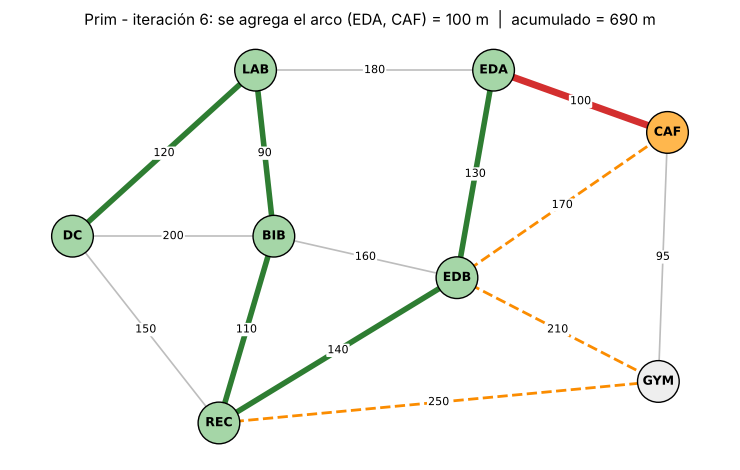

In [12]:
paso = next(pasos)
mostrar_paso(paso)

## Iteración 7 de 7

Último nodo: GYM. CAF–GYM (95 m) es la opción más barata frente a REC–GYM (250) o EDB–GYM (210).

ITERACIÓN 7
Conjunto conectado C : ['DC', 'LAB', 'BIB', 'REC', 'EDB', 'EDA', 'CAF'] -> se agrega GYM
Conjunto no conectado: []

Arcos de la frontera (ordenados por longitud):
desde (C) hacia (no C)  metros            decisión
      CAF          GYM      95 <-- MENOR: se elige
      EDB          GYM     210                    
      REC          GYM     250                    

Arco elegido: (CAF, GYM) con 95 m  |  Costo acumulado = 785 m


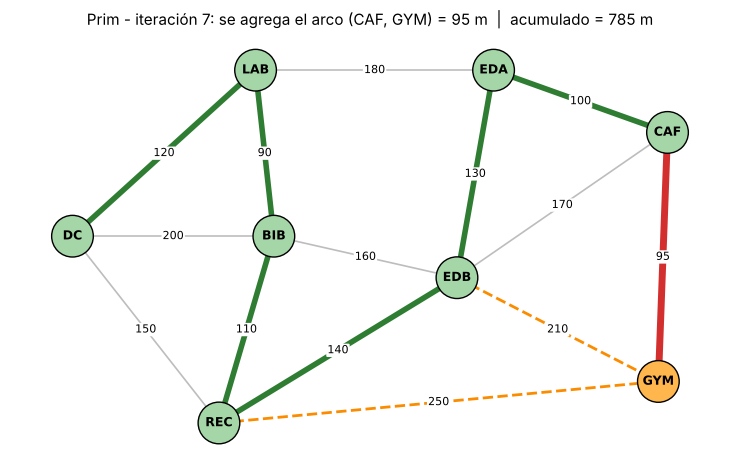

In [13]:
paso = next(pasos)
mostrar_paso(paso)

---
# 8. Visualización de resultados

## 8.1 Árbol de expansión mínima obtenido

Terminadas las $n-1=7$ iteraciones, todos los nodos están en el conjunto conectado. Se muestra la tabla con los arcos del árbol, el **costo acumulado** y una comparación gráfica entre la **red original** y la **solución**.

 iteración desde hacia  metros  acumulado (m)
         1    DC   LAB     120            120
         2   LAB   BIB      90            210
         3   BIB   REC     110            320
         4   REC   EDB     140            460
         5   EDB   EDA     130            590
         6   EDA   CAF     100            690
         7   CAF   GYM      95            785

Número de arcos del árbol : 7 (= n - 1 = 7 )
Z = 120 + 90 + 110 + 140 + 130 + 100 + 95 = 785 metros


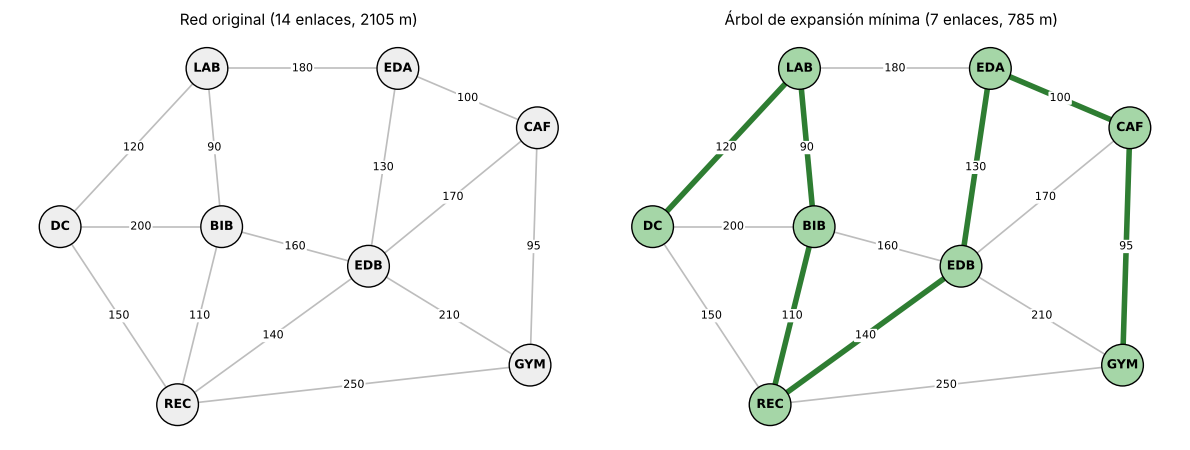

In [14]:
arbol_final = paso["arbol"]
costo_total = paso["total"]

df_arbol = pd.DataFrame(arbol_final, columns=["desde", "hacia", "metros"])
df_arbol.insert(0, "iteración", range(1, len(df_arbol) + 1))
df_arbol["acumulado (m)"] = df_arbol["metros"].cumsum()
print(df_arbol.to_string(index=False))
print()
print("Número de arcos del árbol :", len(arbol_final), "(= n - 1 =", len(nodos) - 1, ")")
print("Z = " + " + ".join(str(w) for _, _, w in arbol_final) + f" = {costo_total} metros")

# Original vs solucion
fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
dibujar(G, pos, "Red original (14 enlaces, 2105 m)", ax=axs[0])
dibujar(G, pos, f"Árbol de expansión mínima (7 enlaces, {costo_total} m)", arbol=arbol_final,
        conectados=nodos, ax=axs[1])
plt.tight_layout()
plt.show()

---
## 8.2 Evolución del costo acumulado

Esta gráfica muestra cómo se va construyendo el costo total de la solución en cada iteración (el color de cada barra indica el arco agregado).

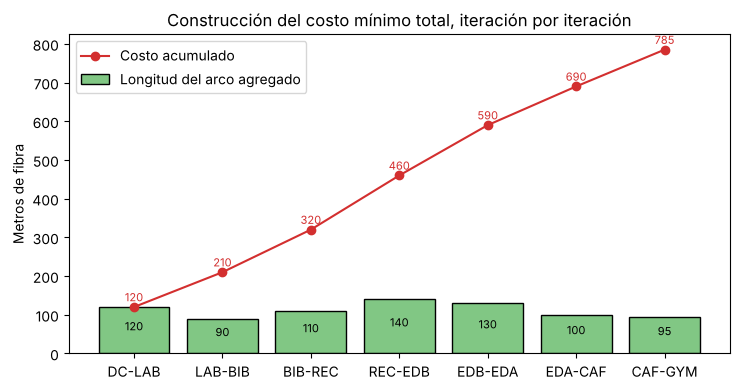

In [15]:
fig, ax = plt.subplots(figsize=(7.5, 4))
etiquetas = [f"{u}-{v}" for u, v, _ in arbol_final]
ax.bar(etiquetas, df_arbol["metros"], color="#81c784", edgecolor="black", label="Longitud del arco agregado")
ax.plot(etiquetas, df_arbol["acumulado (m)"], "o-", color="#d32f2f", label="Costo acumulado")
for i, (a, b) in enumerate(zip(df_arbol["metros"], df_arbol["acumulado (m)"])):
    ax.text(i, a / 2, str(a), ha="center", fontsize=8)
    ax.text(i, b + 15, str(b), ha="center", fontsize=8, color="#d32f2f")
ax.set_ylabel("Metros de fibra")
ax.set_title("Construcción del costo mínimo total, iteración por iteración")
ax.legend()
plt.tight_layout()
plt.show()

---
## 8.3 Verificación con el método matricial visto en clase

Se repite el cálculo con el **método de la matriz**: se marca un nodo como conectado, se "tacha" su columna y se busca el menor coeficiente de las filas de los nodos ya conectados entre las columnas no tachadas. En el mapa de calor se **encierran en rojo** los coeficientes elegidos en cada paso.

Se conecta DC -> LAB  (120 m)
Se conecta LAB -> BIB  (90 m)
Se conecta BIB -> REC  (110 m)
Se conecta REC -> EDB  (140 m)
Se conecta EDB -> EDA  (130 m)
Se conecta EDA -> CAF  (100 m)
Se conecta CAF -> GYM  (95 m)

Costo total por método matricial: 785 m


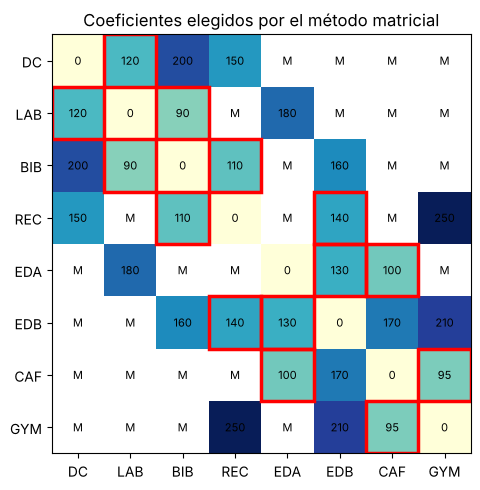

In [16]:
conectado = [idx["DC"]]
elegidos = []
while len(conectado) < n:
    mejor = (None, None, np.inf)
    for i in conectado:
        for j in range(n):
            if j not in conectado and M[i, j] < mejor[2]:
                mejor = (i, j, M[i, j])
    i, j, w = mejor
    conectado.append(j)
    elegidos.append((i, j, w))
    print(f"Se conecta {nodos[i]} -> {nodos[j]}  ({int(w)} m)")

print("\nCosto total por método matricial:", int(sum(w for _, _, w in elegidos)), "m")

fig, ax = plt.subplots(figsize=(6.2, 5))
ax.imshow(Mp, cmap="YlGnBu")
ax.set_xticks(range(n)); ax.set_xticklabels(nodos)
ax.set_yticks(range(n)); ax.set_yticklabels(nodos)
for i in range(n):
    for j in range(n):
        ax.text(j, i, "M" if np.isinf(M[i, j]) else int(M[i, j]), ha="center", va="center", fontsize=8)
for k, (i, j, w) in enumerate(elegidos, start=1):
    for (a, b) in [(i, j), (j, i)]:
        ax.add_patch(plt.Rectangle((b - 0.5, a - 0.5), 1, 1, fill=False, ec="red", lw=2.5))
ax.set_title("Coeficientes elegidos por el método matricial")
plt.tight_layout()
plt.show()

---
## 8.4 Validación con NetworkX (Prim y Kruskal)

Para comprobar que la implementación es correcta se compara con las funciones de la biblioteca **NetworkX**, usando los algoritmos de **Prim** y **Kruskal**. Si todo es correcto los tres costos deben coincidir.

Costo con nuestra implementación de Prim : 785
Costo con NetworkX (Prim)                : 785.0
Costo con NetworkX (Kruskal)             : 785.0
¿Mismos arcos que Kruskal? -> True


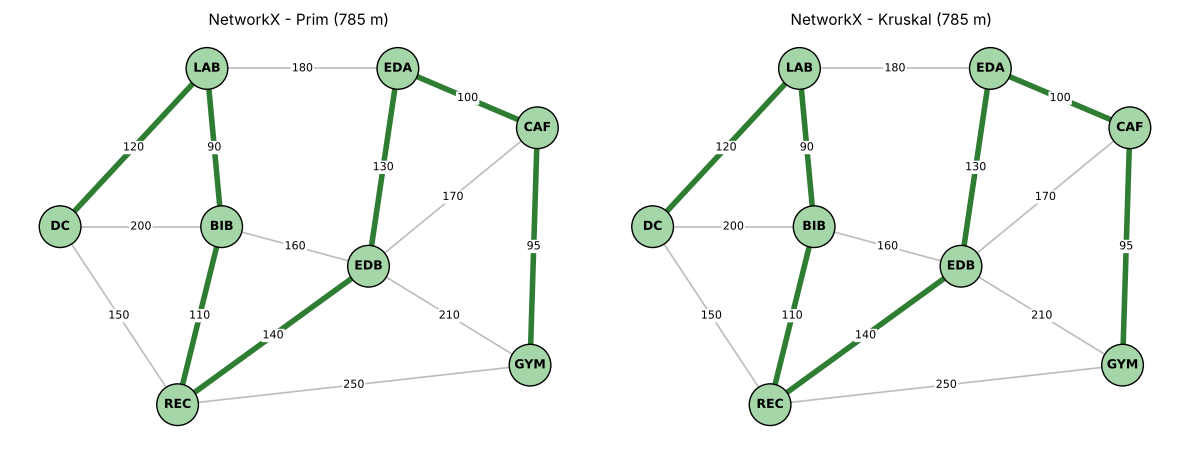

In [17]:
T_prim = nx.minimum_spanning_tree(G, algorithm="prim")
T_krus = nx.minimum_spanning_tree(G, algorithm="kruskal")
c_prim = T_prim.size(weight="weight")
c_krus = T_krus.size(weight="weight")

print("Costo con nuestra implementación de Prim :", costo_total)
print("Costo con NetworkX (Prim)                :", c_prim)
print("Costo con NetworkX (Kruskal)             :", c_krus)

mio = {frozenset((u, v)) for u, v, _ in arbol_final}
nx_k = {frozenset(e) for e in T_krus.edges()}
print("¿Mismos arcos que Kruskal? ->", mio == nx_k)

fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
dibujar(G, pos, f"NetworkX - Prim ({c_prim:.0f} m)", arbol=list(T_prim.edges()), conectados=nodos, ax=axs[0])
dibujar(G, pos, f"NetworkX - Kruskal ({c_krus:.0f} m)", arbol=list(T_krus.edges()), conectados=nodos, ax=axs[1])
plt.tight_layout()
plt.show()

---
## 8.5 Análisis de ahorro y de redundancia (aplicación a TI)

El árbol de expansión mínima minimiza el costo, pero **no ofrece redundancia**: si falla un solo enlace, la red se divide. Se calcula (a) el ahorro frente a tender todos los enlaces posibles, (b) un costo económico *supuesto* de la obra y (c) cuál sería el enlace más barato que se podría agregar para crear un **anillo** de respaldo.

Todos los enlaces posibles : 2105 m
Árbol de expansión mínima  : 785 m
Ahorro                     : 1320 m (62.7 %)

Costo estimado (supuesto de $45/m): $35,325

Enlace redundante más barato: DC-REC (150 m)
Ciclo (anillo) que cierra: DC -> LAB -> BIB -> REC -> DC


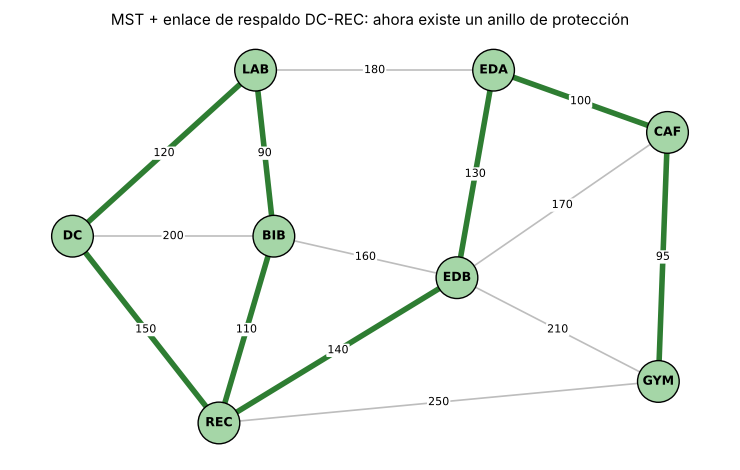

In [18]:
total_posible = sum(w for _, _, w in aristas)
ahorro = total_posible - costo_total
print(f"Todos los enlaces posibles : {total_posible} m")
print(f"Árbol de expansión mínima  : {costo_total} m")
print(f"Ahorro                     : {ahorro} m ({100 * ahorro / total_posible:.1f} %)")

costo_por_metro = 45   # SUPUESTO ilustrativo, en pesos por metro de fibra instalada
print(f"\nCosto estimado (supuesto de ${costo_por_metro}/m): ${costo_total * costo_por_metro:,.0f}")

# Enlace de respaldo mas barato (arco que no esta en el arbol)
no_usados = sorted([(w, u, v) for u, v, w in aristas if frozenset((u, v)) not in mio])
w, u, v = no_usados[0]
print(f"\nEnlace redundante más barato: {u}-{v} ({w} m)")
G_anillo = G.copy()
camino = nx.shortest_path(T_krus, u, v)
print("Ciclo (anillo) que cierra:", " -> ".join(camino + [u]))

fig, ax = plt.subplots(figsize=(7.5, 4.8))
dibujar(G, pos, f"MST + enlace de respaldo {u}-{v}: ahora existe un anillo de protección",
        arbol=arbol_final + [(u, v, w)], conectados=nodos, ax=ax)
plt.tight_layout()
plt.show()


---
# 9. Interpretación de resultados y análisis final

**Resultado principal.** El árbol de expansión mínima conecta los 8 sitios con **7 enlaces** y una longitud total de **785 m** de fibra óptica:

| Enlace | Metros |
|:-------|-------:|
| DC – LAB | 120 |
| LAB – BIB | 90 |
| BIB – REC | 110 |
| REC – EDB | 140 |
| EDB – EDA | 130 |
| EDA – CAF | 100 |
| CAF – GYM | 95 |
| **Total** | **785** |

**Interpretación.**

- Tender los 14 enlaces posibles requeriría 2105 m; la solución óptima usa sólo **785 m**, es decir, un **ahorro de 1320 m (62.7 %)**. Con el costo *supuesto* de \$45 por metro, la obra costaría alrededor de \$35,325.
- El árbol tiene exactamente $n-1=7$ arcos y **no contiene ciclos**, como exige la teoría. Todas las longitudes de la red son distintas, por lo que esta solución es **única** y coincide con la obtenida con el método matricial y con NetworkX (Prim y Kruskal).
- Prim eligió siempre el enlace más barato de la frontera (*estrategia voraz*), y para el MST esa estrategia garantiza el óptimo global.

**Aplicación al área de Tecnologías de la Información.**

- El resultado es un diseño de **topología troncal de costo mínimo** para interconectar edificios de un campus, aplicable a cableado estructurado, enlaces de fibra, redes de sensores IoT o interconexión de sucursales.
- La solución obtenida resulta una **cadena lineal** (DC–LAB–BIB–REC–EDB–EDA–CAF–GYM). En términos de ingeniería de redes esto significa que **un solo corte de fibra aísla parte del campus**. Por eso, un diseño real debe complementar el MST con enlaces redundantes; el más económico es **DC–REC (150 m)**, que cierra un anillo con DC–LAB–BIB–REC y aumenta el costo sólo 150 m (19 %).
- El MST minimiza **costo**, no **latencia** ni **disponibilidad**; para esos criterios se combinan otros modelos (ruta más corta, flujo máximo).

---

# 10. Conclusiones individuales y del equipo

## Conclusión del equipo

El algoritmo de Prim permitió resolver, de forma sistemática y verificable, el problema de conectar todos los sitios del campus con el menor costo de cableado: **785 m**. La implementación paso a paso en Python mostró cómo se construye la solución arco por arco y cómo la representación matricial, la estructura de grafo y las funciones de NetworkX llevan al mismo resultado. También se concluyó que el modelo debe complementarse con criterios de redundancia al diseñar redes reales.

## Conclusión individual

**Integrante 1 – Fernando Dante Rodriguez Silva:** Con esta práctica entendí mucho mejor cómo funciona el algoritmo de Prim paso a paso, sobre todo cómo se va armando la frontera entre los sitios que ya están conectados y los que faltan por conectar sin que se formen ciclos. Al principio me costó un poco seguirle el hilo a tantos arcos candidatos en cada iteración para no confundirme con cuál era el más corto, pero ver cómo iban cambiando de color las líneas y los nodos en cada gráfica lo hizo bastante claro. Este modelo lo aplicaría para planear el cableado estructurado de edificios, redes eléctricas o hasta tuberías donde se busque gastar lo menos posible en material.

**Integrante 2 – Jonathan Alberto López Fabián:** Lo que más me sirvió de esta actividad fue comprobar en Python que tanto el método paso a paso, el método de la matriz que vimos en clase y las funciones de Prim y Kruskal en `NetworkX` llegan exactamente al mismo resultado de 785 metros. La parte que más trabajo me costó fue armar la matriz de adyacencia con valores infinitos (`M`) donde no había enlace y cuidar que quedara simétrica al ser una red no dirigida. Lo aplicaría en el diseño de redes de campus o sucursales, tomando en cuenta lo que vimos al final: que el árbol mínimo ahorra mucho cable, pero conviene agregar al menos un enlace de respaldo como `DC–REC` para cerrar un anillo y que no se caiga toda la red si se corta una fibra.

**Integrante 3 – Brayan Michel Aguilar Torres:** En esta práctica aprendí a calcular cuánto cable y dinero se puede ahorrar al optimizar una topología de red, viendo cómo bajamos de 2,105 metros posibles a solo 785 metros (un ahorro de más del 62 %). Mi principal dificultad fue entender al inicio por qué el árbol resultante quedó prácticamente como una cadena lineal de un extremo al otro del campus y qué desventajas tiene eso en la vida real si falla un enlace. Este tipo de algoritmos los usaría para interconectar redes de sensores IoT, antenas o enlaces entre oficinas donde el presupuesto de instalación es limitado.